In [1]:
#!pip install geopandas scikit-learn matplotlib scipy

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.precision", 2)
RANDOM_SEED = 42   # keeps results reproducible for everyone in the class

# GG4257 - Creating Sustainable Cities with Spatial Data Science
## Lab 6 Challenge 1
All code cells will include a brief explanation of that code line unless included in lab, in cases where I have used websites or documentation, please refer to the [x] section of the 'references' cell at the end of the notebook to view citations.
### 220016532

### Landon Evans
#### Student ID : _220016532_
#### Github : _land0nevans_
#### URL : https://github.com/land0nevans/UA-Lab2

#### Part 1:

I have chose to use Birmingham as my city, as I plan to use this in my IRP and would help to get familiar with the data sources and boundaries I will need.

The main goal of my geodemographic classification will be for marketing, particularly for any housing/letting agencies as I will base this classification on different types of rental markets (e.g family homes, student lets, professionals in the city etc.) so marketing efforts can be directed more effectively to each of these groups. This could help time letting advertisements more effectively around semester times for students, where to prioritise long-term family rentals etc.

#### Part 2:

I have used several datasets from NOMIS (https://www.nomisweb.co.uk), I first looked over these generally and explored columns without needing to download the entire datasets.

#### Part 3:

I have downloaded a variety of topics related to my purpose; including Age, Household Composition, Accommodation Type, Car / Van Availability (to confirm whether space for parking is required), Number of Bedrooms (to identify single-person lets), Tenure, NS-SeC (to target higher-income individuals with premium flats) and Economic Activity.

When downloading the files, I filtered them to only include Birmingham Output Areas, and excluded columns that were repetitive or not necessary for my classification, which reduced the amount of preprocessing required after the merge. In doing this, I noticed that sometimes the tables had confusing names, so I made some small notes to save myself confusion in the later normalisation steps.

Metadata notes :
- TS003: One-person household: Other is the column for one-person households under 66
- TS003: Other household types includes any other single unrelated adults sharing a house e.g roommates/house shares

In [2]:
import pandas as pd
import os

csv_directory = "data_lab6"

# We need a list of all CSV files in the folder
csv_files = [file for file in os.listdir(csv_directory) if file.endswith(".csv")]

# An empty DataFrame to store the merged data
merged_data = pd.DataFrame()

# Loop through each CSV file
for csv_file in csv_files:
    csv_path = os.path.join(csv_directory, csv_file) # We create a consistent path
    df_csv = pd.read_csv(csv_path, low_memory=False) #read each file
    # Concatenate/Merge all columns, there is a pitfall here, you will get a duplicate oa_code from all csv files.
    merged_data = pd.concat([merged_data, df_csv], axis=1)


merged_data.to_csv("data_lab6/merged_census_data.csv")

In [3]:
import geopandas as gpd

shp_path = "data_lab6/Output_Areas_2021_EW_BGC_V2_Birmingham.gpkg"
gdf = gpd.read_file(shp_path)

csv_path = "data_lab6/merged_census_data.csv"
csv_data = pd.read_csv(csv_path, low_memory=False)

# Merge the GeoDataFrame with the DataFrame based on the oa code
merged_data = gdf.merge(csv_data, left_on='OA21CD', right_on='2021 output area', how='left')


In [4]:
# removing unnecessary columns

list(merged_data.columns)
merged_data = merged_data.drop(columns=['LSOA21CD', 'LSOA21NMW','Unnamed: 0','2021 output area','2021 output area.2','2021 output area.3','2021 output area.5','2021 output area.6','2021 output area.7','2021 output area.8'])

#### Part 4:

In [46]:
#merged_data['Private rented: Private landlord or letting agency'].describe()
#merged_data['L15 Full-time students'].describe()

In [6]:
#merged_data.columns[merged_data.columns.duplicated()]

C:\Users\l4nd0\miniforge3\envs\ua2\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\l4nd0\miniforge3\envs\ua2\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\l4nd0\miniforge3\envs\ua2\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\l4nd0\miniforge3\envs\ua2\lib\site

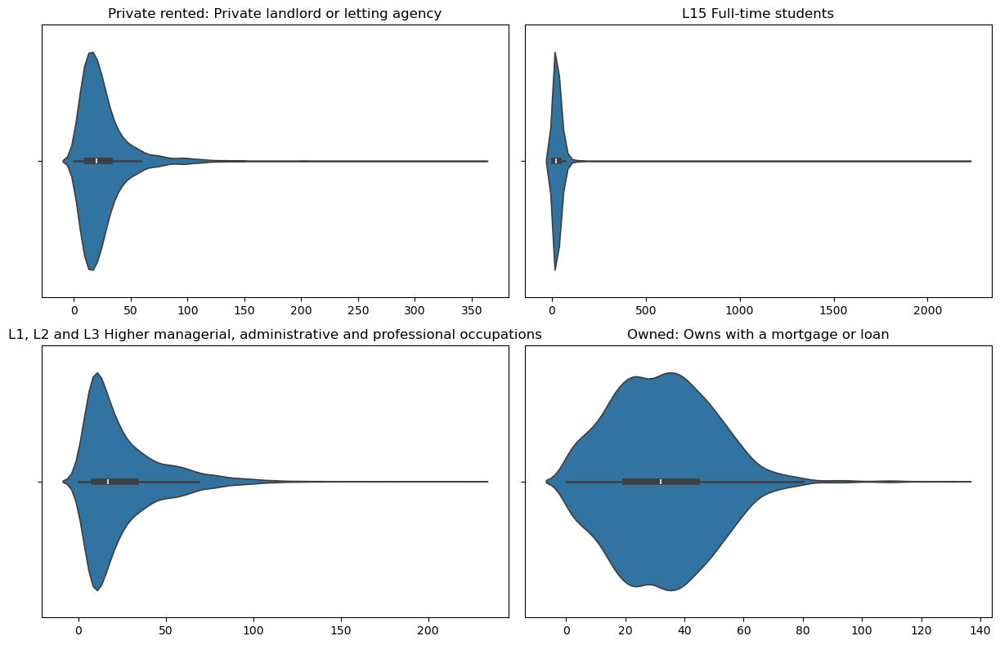

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

attributes_to_plot = ['Private rented: Private landlord or letting agency',
                      'L15 Full-time students',
                      'L1, L2 and L3 Higher managerial, administrative and professional occupations',
                      'Owned: Owns with a mortgage or loan']

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.violinplot(x=merged_data[attribute])
    plt.title(attribute)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

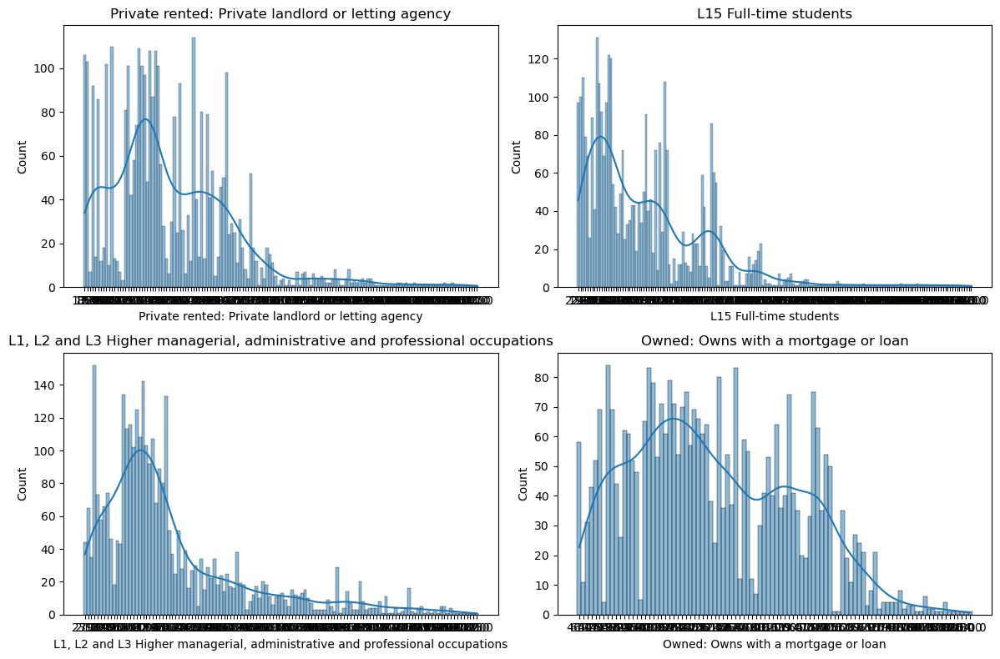

In [8]:
import matplotlib.pyplot as plt

attributes_to_plot = ['Private rented: Private landlord or letting agency',
                      'L15 Full-time students',
                      'L1, L2 and L3 Higher managerial, administrative and professional occupations',
                      'Owned: Owns with a mortgage or loan']

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.histplot(merged_data[attribute].astype(str), kde=True)
    plt.title(attribute)

plt.tight_layout()
plt.show()

The DEA reveals that, from the violin plots, most output areas have around 20-35 renting households, though there is a very long tail reaching around 350 in some OAs, which likely represent flats in the inner and immediate outer city areas. The student violin plot shows that most areas have very few students, roughly less than 100, but the long tail suggests there is atleast one area with 2200. For the purpose of this geodemographic classification in targeting different rental audiences, I think this variable is particularly important as a target group as student incomes, needs and rental terms are very different. Ownership varies much more across different areas, and is an important variable in trying to cluster owned areas differently to rental areas.

#### Part 5

Here I check whether the dataset has any missing values and confirm there are none.
When attempting the next step (taking total and value columns), I noticed that the column totals were very unclear for each csv I had downloaded, and this required renaming in Excel.

In [9]:
#merged_data.isna().sum()

In [10]:
def calculate_percentages(dataframe, total_columns, value_columns):

    result_df = pd.DataFrame()

    for total_col, value_col in zip(total_columns, value_columns):
        percentage_col_name = f"{value_col}_percentage"

        if total_col not in dataframe.columns:
            raise ValueError(f"Total column '{total_col}' not found in the DataFrame.")
        # The data have several empty values, so you need to process them, forcing them to be a numeric or NaN value
        dataframe[value_col] = pd.to_numeric(dataframe[value_col], errors='coerce')
        dataframe[total_col] = pd.to_numeric(dataframe[total_col], errors='coerce')
        
        result_df[percentage_col_name] = (dataframe[value_col] / dataframe[total_col]) * 100

    return result_df

# List of the corresponding totals.
total_cols = ['Total_Residents', 'Total_Residents',
              'Total_Age', 'Total_Age', 'Total_Age',
              'Total_Accom', 'Total_Accom', 'Total_Accom',
              'Total_Cars',
              'Total_Bedrooms',
              'Total_Tenure', 'Total_Tenure', 'Total_Tenure', 'Total_Tenure',
              'Total_NSSEC', 'Total_NSSEC',
              'Total_Migration']
# List of the corresponding values. 
value_cols = ['One-person household: Other',
              'Other household types',
              'Aged 20 to 24 years',
              'Aged 25 to 29 years',
              'Aged 65 to 69 years',
              'Terraced',
              'In a purpose-built block of flats or tenement',
              'Part of a converted or shared house, including bedsits',
              'No cars or vans in household',
              '1 bedroom',
              'Owned: Owns with a mortgage or loan',
              'Owned: Owns outright',
              'Social rented',
              'Private rented: Private landlord or letting agency',
              'L1, L2 and L3 Higher managerial, administrative and professional occupations',
              'L15 Full-time students',
              'Migrant from within the UK: Address one year ago was in the UK'
             ]

# Later we migth need to rename those columns., for now is ok...
result_dataframe = calculate_percentages(merged_data, total_cols, value_cols)

In [11]:
# Concatenate the resulting tables.
concatenated_df = pd.concat([merged_data, result_dataframe], axis=1, ignore_index=False)
#concatenated_df.head()

In [12]:
#list(concatenated_df.columns)

In [13]:
# Subsetting the attributes we need, we dont need the total for now.
keep_cols= ['One-person household: Other_percentage',
            'Other household types_percentage',
            'Aged 20 to 24 years_percentage',
            'Aged 25 to 29 years_percentage',
            'Aged 65 to 69 years_percentage',
            'Terraced_percentage',
            'In a purpose-built block of flats or tenement_percentage',
            'Part of a converted or shared house, including bedsits_percentage',
            'No cars or vans in household_percentage',
            '1 bedroom_percentage',
            'Owned: Owns with a mortgage or loan_percentage',
            'Owned: Owns outright_percentage',
            'Social rented_percentage',
            'Private rented: Private landlord or letting agency_percentage',
            'L1, L2 and L3 Higher managerial, administrative and professional occupations_percentage',
            'L15 Full-time students_percentage',
            'Migrant from within the UK: Address one year ago was in the UK_percentage',
            'OA21CD', 
            'LAT',
            'LONG',
            'geometry',
            'LSOA21NM',
            'BNG_N',
            'BNG_E'
              ]

bham_census_data = concatenated_df[keep_cols]

In [14]:
# For more easy manipulation we define short column names
short_column_names = {
    'One-person household: Other_percentage': 'OnePerson_under66',
    'Other household types_percentage': 'Other_HH',
    'Aged 20 to 24 years_percentage': '20to24',
    'Aged 25 to 29 years_percentage': '25to29',
    'Aged 65 to 69 years_percentage': '65to69',
    'Terraced_percentage':'Terraced',
    'In a purpose-built block of flats or tenement_percentage': 'Flats_Tnmt',
    'Part of a converted or shared house, including bedsits_percentage': 'Shared_BdSt',
    'No cars or vans in household_percentage': 'NoCar',
    '1 bedroom_percentage': '1Bed',
    'Owned: Owns with a mortgage or loan_percentage': 'Owned_Mortgage',
    'Owned: Owns outright_percentage': 'Owned_Outright',
    'Social rented_percentage': 'Social_Rent',
    'Private rented: Private landlord or letting agency_percentage': 'Private_Rent',
    'L1, L2 and L3 Higher managerial, administrative and professional occupations_percentage': 'L1L2L3',
    'L15 Full-time students_percentage': 'L15',
    'Migrant from within the UK: Address one year ago was in the UK_percentage': 'UK_Migrant'
}


bham_census_data = bham_census_data.rename(columns=short_column_names)

In [15]:
#bham_census_data.info

#### Part 6:

In [16]:
# Calculate z-score for each column, but we need to initially filter only the float attributes.
# bcs you can't calculate that for the OA code.. :P

numeric_columns = bham_census_data.select_dtypes(include='float64')
z_score_df = (numeric_columns - numeric_columns.mean()) / numeric_columns.std(ddof=0)
#z_score_df.head()

In [17]:
z_score_df.shape

(3325, 19)

In [18]:
corr = z_score_df.corr()
#corr.style.background_gradient(cmap='coolwarm')

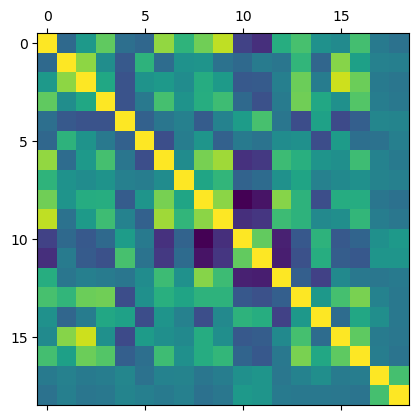

In [19]:
import matplotlib.pyplot as plt

plt.matshow(z_score_df.corr())
plt.show()

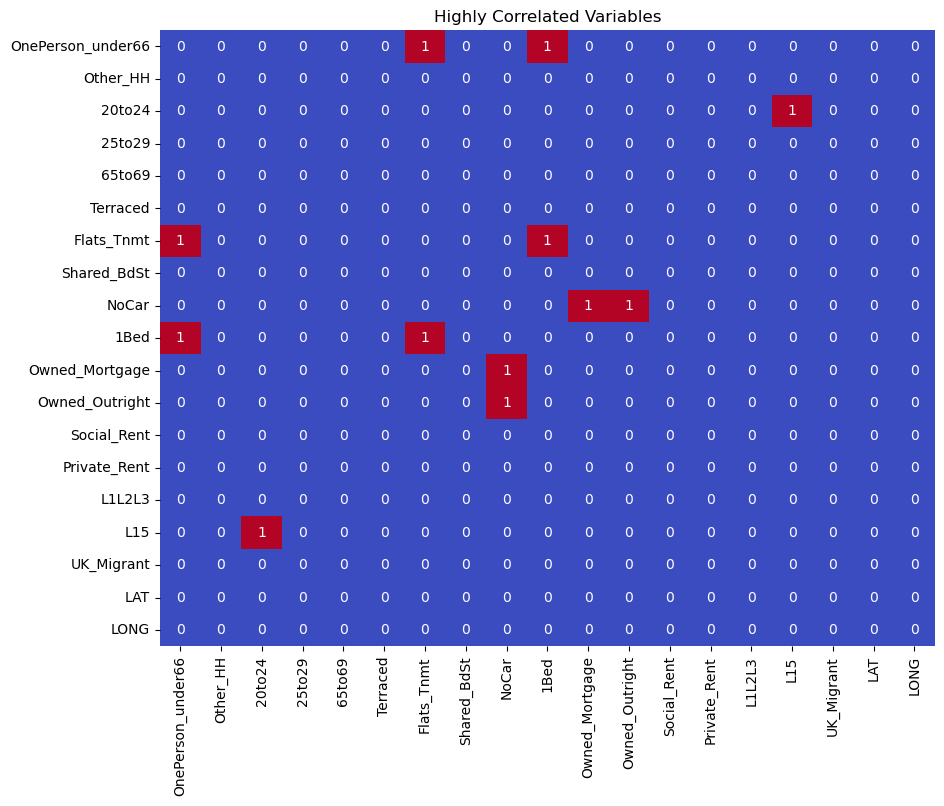

In [20]:
threshold = 0.7 

highly_correlated = (corr.abs() > threshold) & (corr.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated, cmap='coolwarm', cbar=False, annot=True)

plt.title('Highly Correlated Variables')
plt.show()


In [21]:
# now i drop the most correlated variables, so they are not over-weighted in k-means

z_score_df.drop(['1Bed', 'OnePerson_under66', 'NoCar', '20to24', 'LAT', 'LONG'], axis=1, inplace=True) # i chose to drop 20to24, as L15 is a more specific variable for students, which is a more targeted group for marketing
                                                                                        # i also luckily noticed i had to drop LAT and LONG
#z_score_df.info()

In [22]:
#checking removing these columns fixed correlation problems, i also checked for NaNs


#threshold = 0.7
#highly_correlated_2 = (corr_2.abs() > threshold) & (corr_2.abs() < 1.0)

#plt.figure(figsize=(10, 8))
#sns.heatmap(highly_correlated_2, cmap='coolwarm', cbar=False, annot=True)

#plt.title('New Highly Correlated Variables')
#plt.show()
#z_score_df.isna().any().any()

#### Part 7:

In [23]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist, pdist

# KMeans with 10 clusters
kmeans = KMeans(n_clusters=10)
kmeans.fit(z_score_df)
labels = kmeans.predict(z_score_df)
cluster_centres = kmeans.cluster_centers_
z_score_df['Cluster'] = kmeans.labels_

C:\Users\l4nd0\miniforge3\envs\ua2\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Here I have defined my number of clusters, but I need to find out the optimum number of clusters. I experimented with different values of k here, but used the elbow method to define the optimal number.

(array([778., 685., 108.,  48., 469., 217.,  95., 420., 218., 287.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

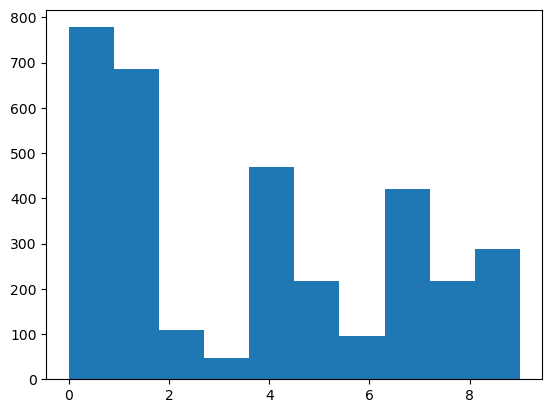

In [24]:
plt.hist(labels)

#### Part 8:

In [25]:
#z_score_df.columns
z_score_df = z_score_df.drop(columns=['Cluster']) # The cluster column was included in my radial plots and odd results in my elbow method

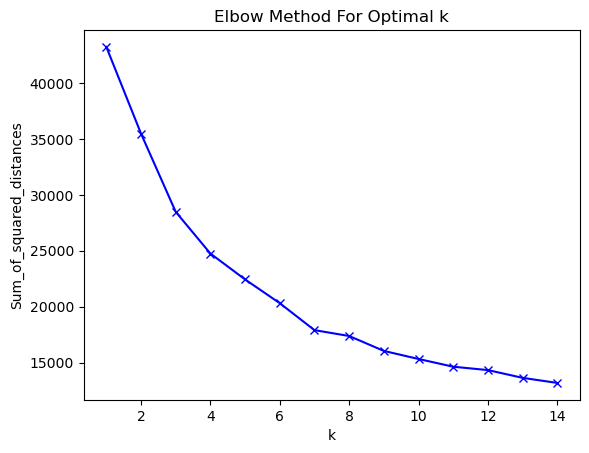

In [26]:
Sum_of_squared_distances = []

K_range = range(1,15)

for k in K_range:
 km = KMeans(n_clusters=k)
 km = km.fit(z_score_df)
 Sum_of_squared_distances.append(km.inertia_)
    
plt.plot(K_range, Sum_of_squared_distances, 'bx-')
plt.xlabel('k')
plt.ylabel('Sum_of_squared_distances')
plt.title('Elbow Method For Optimal k')
plt.show()

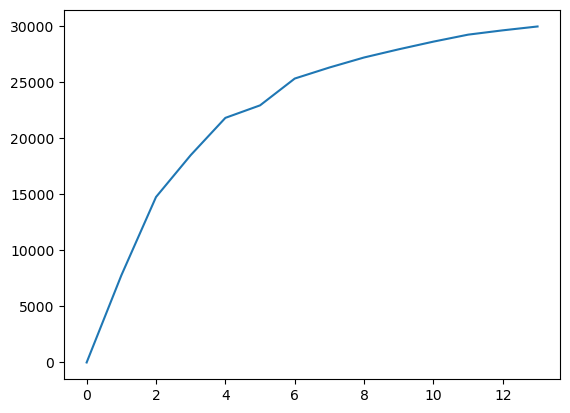

In [27]:
import numpy as np
def elbow(dataframe, n):
    kMeansVar = [KMeans(n_clusters=k).fit(dataframe.values) for k in range(1, n)] #making use of list comprehensions.
    centroids = [X.cluster_centers_ for X in kMeansVar]
    k_euclid = [cdist(dataframe.values, cent) for cent in centroids]
    dist = [np.min(ke, axis=1) for ke in k_euclid]
    wcss = [sum(d**2) for d in dist]
    tss = sum(pdist(dataframe.values)**2)/dataframe.values.shape[0]
    bss = tss - wcss
    plt.plot(bss)
    plt.show()
 
elbow(z_score_df,15)

From the elbow plot, the optimal k value appears to be 4, but there is also an interesting curve at around 7. I decided to create radial plots for both of these values, as I want to classify key groups for marketing purposes and 4 would likely merge some groups together.

#### Part 9:

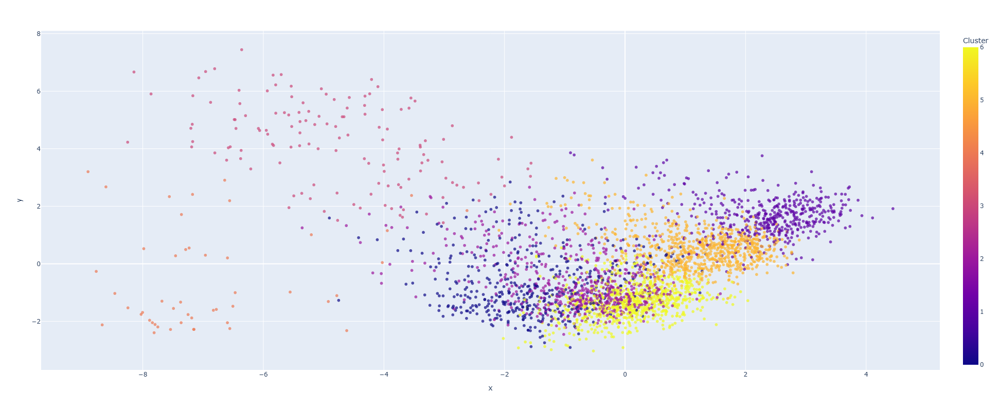

These two components explain 45.60% of the point variability.


<Figure size 1200x800 with 0 Axes>

In [28]:
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plt.figure(figsize=(12, 8))

kmeans = KMeans(n_clusters=7, random_state=RANDOM_SEED) #i decided to manually set the random state using the first cell from the lab throughout, as I ran into confusion each time i restarted the kernel.
clusters = kmeans.fit_predict(z_score_df)

z_score_df['Cluster'] = clusters

scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(z_score_df)

# PCA analysys.
pca = PCA(n_components=2).fit(stand_data_scaled) #PCA with 2 components, we can also use 3 components, but for now we will use 2 to make it easier to visualize the clusters.
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

# Create a scatter plot
fig = px.scatter(x=pca_result[:, 0], y=pca_result[:, 1], color=clusters,
                 labels={'color': 'Cluster'},
                 #title='Cluster Plot against 1st 2 Principal Components',
                 opacity=0.7,
                 width=800, 
                 height=800)

plt.tight_layout()
fig.show()

print(f"These two components explain {(variance_ratio.sum()*100):.2f}% of the point variability.")


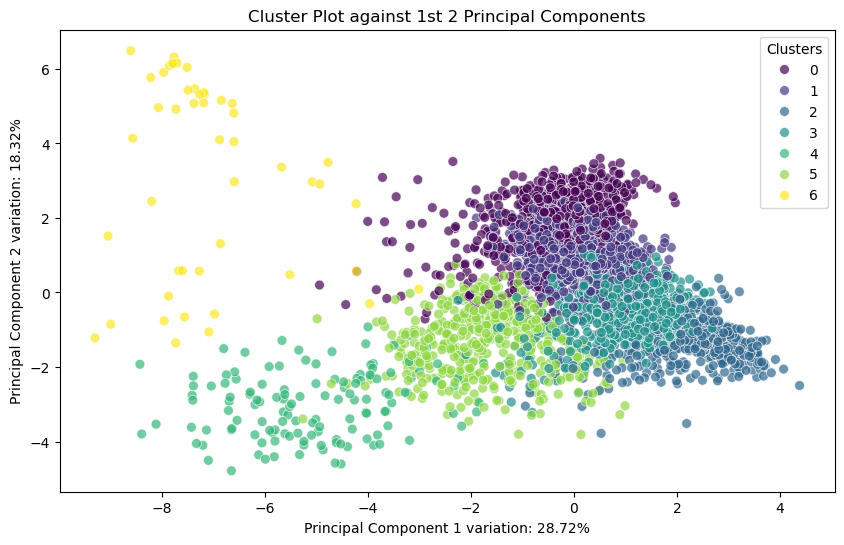

In [29]:

kmeans = KMeans(n_clusters=7, random_state=RANDOM_SEED) 
clusters = kmeans.fit_predict(z_score_df)

z_score_df['Cluster'] = clusters

# Standardize the data for PCA
scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(z_score_df)

# PCA
pca = PCA(n_components=2).fit(stand_data_scaled)
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=clusters, palette='viridis', s=50, alpha=0.7)
plt.title('Cluster Plot against 1st 2 Principal Components')
plt.xlabel(f'Principal Component 1 variation: {variance_ratio[0]*100:.2f}%')
plt.ylabel(f'Principal Component 2 variation: {variance_ratio[1]*100:.2f}%')
plt.legend(title='Clusters')
plt.show()


PCA plots explain around 45.6% of the variation, one cluster is very spread out (6, which may show where student numbers are above average) as well as cluster 4 , while a lot of the others overlap and are not accurately represented by two components alone. I use radial plots in the next cells to understand the clusters better. 

In [30]:
# k value 4
kmeans_4 = KMeans(n_clusters=4)
clusters_4 = kmeans_4.fit_predict(z_score_df)

# Get the cluster centers
cluster_centers_4 = kmeans.cluster_centers_


# Get the cluster centers
cluster_centers_4 = pd.DataFrame(kmeans_4.cluster_centers_, columns=z_score_df.columns)

# Create a new DataFrame with cluster assignments and column names
#result_df = pd.DataFrame({'Cluster': clusters, 'Column': z_score_df.columns})

#cluster_centers_4.head(6)

# k value 7
kmeans_7 = KMeans(n_clusters=7, random_state=RANDOM_SEED)
clusters_7 = kmeans_7.fit_predict(z_score_df)

# Get the cluster centers
cluster_centers_7 = kmeans.cluster_centers_


# Get the cluster centers
cluster_centers_7 = pd.DataFrame(kmeans_7.cluster_centers_, columns=z_score_df.columns)

In [31]:
# K VALUE = 4
#first_row_centers = cluster_centers_4.iloc[0, :]

# len of features
#num_features = len(first_row_centers)

# polar coordinates
#theta = np.linspace(0, 2 * np.pi, num_features, endpoint=False)  

#fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
#ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
#ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

#ax.set_xticks(theta)
#ax.set_xticklabels(cluster_centers_4.columns, rotation=45, ha='right')

#plt.show()
#Ignore the cluster polar values, and focus in he census variables.

At k-4, owned_mortgage and owned_outright are grouped together, and students are not clearly separated, for example, which shows there may be too few clusters for my purpose.

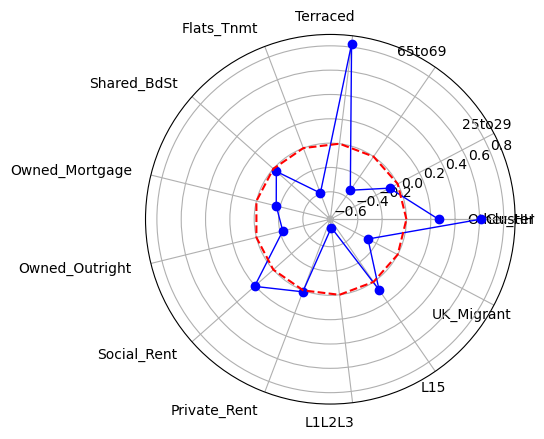

In [32]:
#K VALUE = 7
first_row_centers = cluster_centers_7.iloc[0, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers_7.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

##### Terraced, students and social_rent are included so this group is mixed rental terraced streets.

I decided to go with a k value of 7, as I wanted more distinct groups to group by. In the next cells, I generate radial plots for each cluster so I can name them accurately. I condense the code to take up less space.

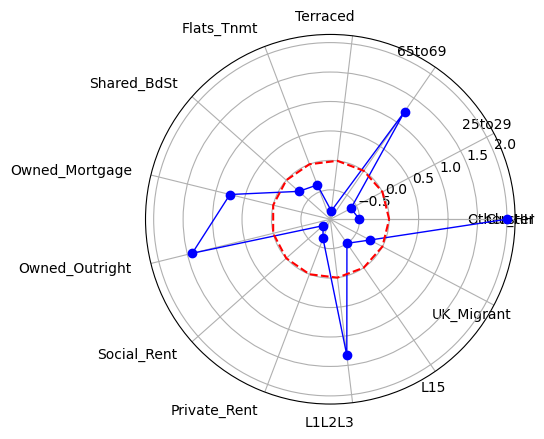

In [33]:
first_row_centers = cluster_centers_7.iloc[1, :]
num_features = len(first_row_centers)
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')
ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers_7.columns, rotation=45, ha='right')
plt.show()

##### Includes L1L2L3 and 65to59, as well as both owned groups. This group represents wealthier, older house owners.

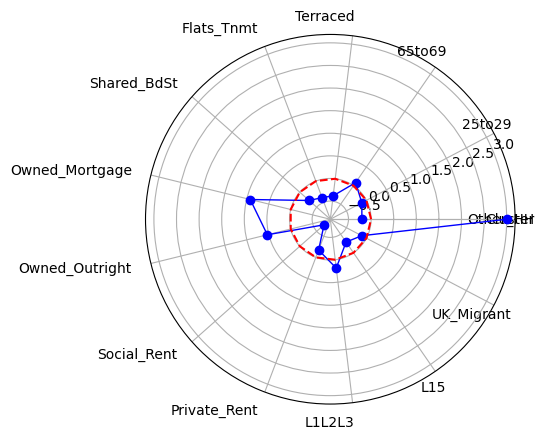

In [34]:
first_row_centers = cluster_centers_7.iloc[2, :]
num_features = len(first_row_centers)
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')
ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers_7.columns, rotation=45, ha='right')
plt.show()

##### Includes owned_mortgage mainly, with some in L1L2L3 but not 65to69, so I considered this group to be younger, working house owners

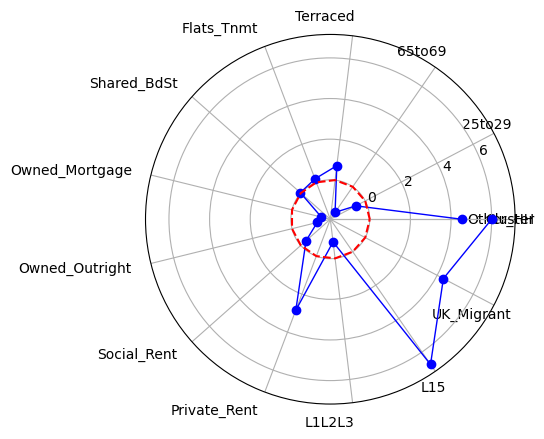

In [35]:
first_row_centers = cluster_centers_7.iloc[3, :]
num_features = len(first_row_centers)
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')
ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers_7.columns, rotation=45, ha='right')
plt.show()

##### Mainly L15(students) UK_migrant and private_rent, so this is a key student group to classify.

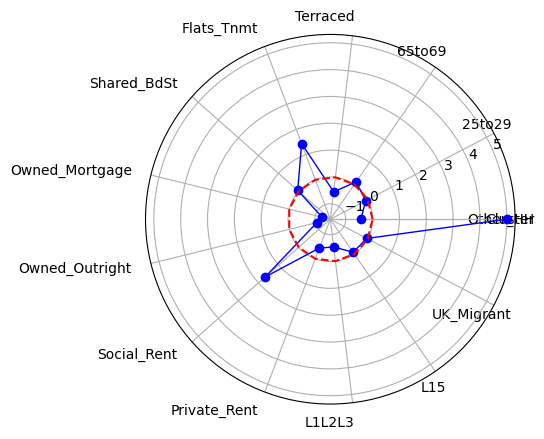

In [36]:
first_row_centers = cluster_centers_7.iloc[4, :]
num_features = len(first_row_centers)
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')
ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers_7.columns, rotation=45, ha='right')
plt.show()

##### Ownership is very low, this cluster includes social_rent and tenement-type houses, so I considered this generally as social housing.

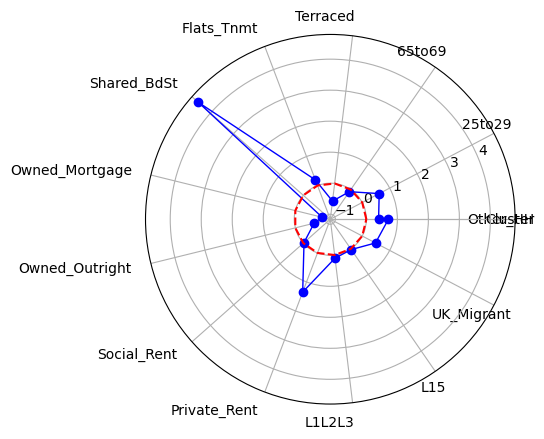

In [37]:
first_row_centers = cluster_centers_7.iloc[5, :]
num_features = len(first_row_centers)
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')
ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers_7.columns, rotation=45, ha='right')
plt.show()

##### Has private_rent and shared / bedsits, as well as 25to29 so is likely renting roommates/shared housing

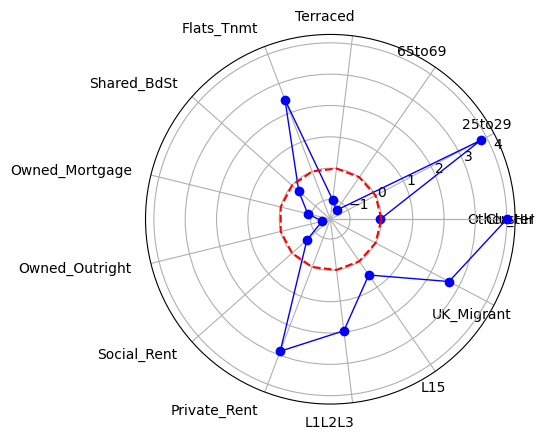

In [38]:
first_row_centers = cluster_centers_7.iloc[6, :]
num_features = len(first_row_centers)
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')
ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers_7.columns, rotation=45, ha='right')
plt.show()

##### Private rent and L1L2L3 aged 25to29, so likely represents young, wealthy professionals or graduates moving into the city (also UK_migrant)

#### Part 10

In [39]:
list(z_score_df.columns)

['Other_HH',
 '25to29',
 '65to69',
 'Terraced',
 'Flats_Tnmt',
 'Shared_BdSt',
 'Owned_Mortgage',
 'Owned_Outright',
 'Social_Rent',
 'Private_Rent',
 'L1L2L3',
 'L15',
 'UK_Migrant',
 'Cluster']

In [40]:
z_score_df.drop([
 'Other_HH',
 '25to29',
 '65to69',
 'Terraced',
 'Flats_Tnmt',
 'Shared_BdSt',
 'Owned_Mortgage',
 'Owned_Outright',
 'Social_Rent',
 'Private_Rent',
 'L1L2L3',
 'L15',
 'UK_Migrant'], axis=1, inplace=True)
z_score_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3325 entries, 0 to 3324
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Cluster  3325 non-null   int32
dtypes: int32(1)
memory usage: 13.1 KB


In [41]:
# Concatenate the resulting tables.
final_df = pd.concat([bham_census_data, z_score_df], axis=1, ignore_index=False)
final_df.head()

,OnePerson_under66,Other_HH,20to24,25to29,65to69,Terraced,Flats_Tnmt,Shared_BdSt,NoCar,1Bed,...,L15,UK_Migrant,OA21CD,LAT,LONG,geometry,LSOA21NM,BNG_N,BNG_E,Cluster
0,14.78,3.48,4.95,4.02,5.26,9.65,0.00,0.00,8.77,0.00,...,8.95,4.69,E00045077,52.45,-1.81,"MULTIPOLYGON (((413029.927 284180.623, 412936....",Birmingham 089B,284061,412860,3
1,15.33,9.33,4.84,4.84,4.84,0.00,0.00,0.00,9.87,0.00,...,6.17,4.86,E00045078,52.45,-1.81,"MULTIPOLYGON (((413018.737 283913.107, 412892....",Birmingham 089D,283774,412872,3
2,31.65,6.33,7.82,7.49,2.93,0.63,61.39,10.76,53.80,51.90,...,8.24,18.83,E00045079,52.45,-1.82,"MULTIPOLYGON (((412209.000 283476.000, 412207....",Birmingham 089E,283318,412161,5
3,15.33,16.06,4.94,5.71,5.97,19.71,0.73,1.46,18.25,5.84,...,8.44,3.97,E00045080,52.45,-1.83,"MULTIPOLYGON (((411823.000 283951.001, 411809....",Birmingham 078D,283736,411780,3
4,24.75,3.96,4.40,4.40,6.80,2.91,53.40,1.94,55.88,44.12,...,4.21,10.76,E00045081,52.45,-1.83,"MULTIPOLYGON (((411850.242 283487.840, 411703....",Birmingham 078D,283514,411773,5


In [42]:
final_df.columns

Index(['OnePerson_under66', 'Other_HH', '20to24', '25to29', '65to69',
       'Terraced', 'Flats_Tnmt', 'Shared_BdSt', 'NoCar', '1Bed',
       'Owned_Mortgage', 'Owned_Outright', 'Social_Rent', 'Private_Rent',
       'L1L2L3', 'L15', 'UK_Migrant', 'OA21CD', 'LAT', 'LONG', 'geometry',
       'LSOA21NM', 'BNG_N', 'BNG_E', 'Cluster'],
      dtype='object')

In [43]:
final_df['Cluster']= clusters_7 # I realised that I had made a mistake using the wrong k_means run, and so my cluster names were not making sense when using my radial plots to define them, and I had to just use these clusters manually.
final_df.explore(column='Cluster', cmap='Set1', tiles='Esri.WorldImagery')

#### Part 11:

In [44]:
def rename_column(x): 
    x = x.replace("0", "Mixed rentals, terraced")
    x = x.replace("1", "Affluent house owners")
    x = x.replace("2", "Mortgaged houses")
    x = x.replace("3", "Student rentals")
    x = x.replace("4", "Council/social housing")
    x = x.replace("5", "Shared flats/bedsits")
    x = x.replace("6", "Central, young professionals")
    return x

final_df['Cluster'] = final_df['Cluster'].astype(str).apply(rename_column)


In [45]:
final_df.explore(column='Cluster', cmap='Set1', tiles='Esri.WorldGrayCanvas')

#### Part 12:

##### Analytical decisions/subjectivity
I chose variables based on housing type, age, socio-economic status, migration and housing type etc. as I thought these would be most useful in sorting key 'clusters' in a housing market, and letting agencies or housing associations could more easily target these groups in marketing or housing schemes. When checking correlation, I removed some variables and kept the one that was most useful in separating key groups (e.g keeping L15(students) rather than 20to24).

When choosing k, I followed the elbow method but tested with k=4 and k=7, as i thought having 4 clusters is incredibly limiting when trying to separate rental markets, particularly in a city like Birmingham where there is a very diverse range of groups. This was a subjective choice, and was influenced by my goal (marketing to specific rental groups) and personal knowledge of the area. My classification may differ from others if they choose different variables or remove different columns at the correlation stage and especially if they choose a different value for k.
##### Challenges / limitations
The census data is taken from 2021, and the market may have changed since. It also may inaccurately represent student numbers if the census was completed when they were not at their term address. The output areas may also seem misleading e.g in the North as these can represent large parks (Sutton Park) which have very few residents. The census data does not include any information related to tenancy length or rent price, so this would need to be considered alongside my classification for marketing to be optimal.

The main challenges arose from rushing when using code provided in the lab and not paying enough attention to unique variable names, as I ran into some confusion where I was attempting to rename my clusters (using my radar plots), but every time I re-ran the code the cluster names did not make much sense. In this scenario, I was lucky enough to notice as I could compare the map with my personal knowledge of the area and realise that I had made a mistake (the incorrect run of kmeans the map was using inaccurately kept labelling Sutton Coldfield as majority mixed rentals, terraced, which i know to not be true). If I was not familiar with the area, I may not have noticed this so this was definitely an important challenge to overcome.

I had some issues when using the elbow method, and found myself confused when re-running cells and getting different results. I removed the 'clusters' column as this was included with my variables and interfering with the curve, and set the random seed to 42, using the first cell from the lab. I had a few other small problems where the lab code did not work exactly (i had to add .astype(str) in cell 45 and change the basemap tiles to avoid the API key error).

##### Use cases
My final classification defines 7 different rental market groups :

- Mixed rentals, terraced
- Affluent house owners
- Mortgaged houses
- Student rentals
- Council/social housing
- Shared flats/bedsits
- Central, young professionals

These groups could be used by a letting agency in targeted marketing and allocating relevant resources to different groups. For example, an office could be set up in key student rental areas, flyers could be distributed and advertisements in Universities can be timed to prioritise months where students are searching for new housing, and where there may be a high turnover of previous students. Using the 'Central, young professional rentals' group an agency can design more premium, higher-quality marketing campaigns or ensure buildings meet the needs of modern professionals (perhaps more amenities, consistent WiFi etc.). Using groups such as both house owner groups or council/social housing, an agency may know that they do not need to target specific areas and save money on marketing, or could tailor communication to house owners who may be downsizing and inclined to rent out their homes.